# Big Data Bowl 2027 — DB Injury Risk from Tracking Data

**Argument:** tracking data can surface injury-risk tendencies in defensive backs that current Combine drills don't measure, so the draft process would benefit from a tracked 1-on-1 Combine drill.

**Plan**
1. **Identify injured DBs** — injury defined through snaps (change point on snap share), cross-checked against injury reports.
2. **Tracking tendencies** — do speed, acceleration, and turning (angle-change rate, speed kept through cuts) decline before injury? Do they fade more within games?
3. **Correlate to the Combine** — do existing drills capture what tracking shows?
3b. **Combine tracking** — does movement inside the agility drills capture it better than drill times?
4. **Propose a 1-on-1 Combine drill** — built around the measure tracking showed to be most informative.

*Guiding principle: one simple project done well.*

---
**Data:** reads `../data/` (run from `Ben_EDA/`). If that folder isn't found, it runs on synthetic demo data from `synthetic_bdb.py` (same folder) so every step can be tested end to end.

## 0. Setup & data loading

Reads the repo's `data/` folder: `game_tracking_<season>.csv`, `games.csv`, `player_play.csv`, `players.csv`, `combine_results.csv`, `combine_tracking.csv`. Snap counts, injury reports, and schedules come from nflverse (`nflreadpy`) for each season. Internally the notebook uses camelCase IDs (`gameId`, `playId`, `nflId`).

In [1]:
# %pip install nflreadpy pyarrow ruptures seaborn scipy matplotlib

from pathlib import Path
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")

# ---------------- config ----------------
DATA_DIR = Path("../data")                 # notebook lives in Ben_EDA/
TRACKING_GLOB = "game_tracking_*.csv"
USE_SYNTHETIC = not (DATA_DIR / "games.csv").exists()

DB_POSITIONS = {"CB", "SS", "FS", "S", "DB"}
OFF_SKILL = {"WR", "TE", "RB"}             # receivers a DB can mirror (Section 4)
SNAP_EVENTS = {"ball_snap", "snap_direct", "autoevent_ballsnap"}

# Step 1 — injury definition
MIN_BASELINE_GAMES = 3      # games of steady usage before an onset counts
BASELINE_MIN_PCT = 0.60     # "regular" = median defensive snap share >= this
DROP_RATIO = 0.50           # onset game: snap share < 50% of baseline
MIN_OUT_GAMES = 1           # must stay low at least this many games after onset
LONG_ABSENCE_GAMES = 4      # unconfirmed absences this long are likely IR (not on weekly report)

# Step 2 — tracking features
MIN_SPEED_FOR_DIR = 2.0     # yd/s; dir is noise below this
HARD_CUT_DEG_S = 150        # turn rate counted as a real break
RETENTION_SEC = 0.5         # speed compared this long before / after a cut
PRE_WINDOW = 2              # last N games before onset = "pre-injury"
MIN_BASE_GAMES_TRK = 2      # tracked games needed before the pre-window
N_CONTROLS = 4              # matched healthy DBs per injured DB

print("Synthetic demo mode" if USE_SYNTHETIC else f"Real data from {DATA_DIR.resolve()}")

Real data from C:\Users\bchm5\TSLR\USC-NFL-Big-Data-Bowl-2027\data


In [2]:
def load_repo_data(data_dir, chunksize=5_000_000):
    """Raw tables in the repo's own schema. Tracking is filtered to DBs + receivers while reading."""
    raw = {k: pd.read_csv(data_dir / f"{k}.csv") for k in ["games", "players", "combine_results"]}
    raw["player_play"] = pd.read_csv(data_dir / "player_play.csv",
                                     usecols=["game_id", "play_id", "nfl_id", "team_abbr", "possession_team",
                                              "quarter", "lined_up_position"])
    keep = set(raw["players"].loc[raw["players"].nfl_position.isin(DB_POSITIONS | OFF_SKILL), "nfl_id"])
    cols = ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "a", "dir", "event"]
    parts = []
    for f in sorted(glob.glob(str(data_dir / TRACKING_GLOB))):
        for chunk in pd.read_csv(f, usecols=cols, chunksize=chunksize):
            parts.append(chunk[chunk.nfl_id.isin(keep)])
        print("loaded", Path(f).name)
    raw["game_tracking"] = pd.concat(parts, ignore_index=True)
    db_keep = set(raw["players"].loc[raw["players"].nfl_position.isin(DB_POSITIONS), "nfl_id"])
    raw["combine_tracking"] = pd.concat(
        c[c.nfl_id.isin(db_keep)] for c in pd.read_csv(data_dir / "combine_tracking.csv", chunksize=chunksize))
    return raw


def load_nflverse(seasons):
    import nflreadpy as nfl
    return dict(snaps=nfl.load_snap_counts(seasons).to_pandas(),
                injuries=nfl.load_injuries(seasons).to_pandas(),
                id_map=nfl.load_players().to_pandas()[["gsis_id", "nfl_id", "pfr_id", "display_name", "position"]],
                schedule=nfl.load_schedules(seasons).to_pandas())


if USE_SYNTHETIC:
    from synthetic_bdb import make_all
    raw = make_all()
else:
    raw = load_repo_data(DATA_DIR)

ids = {"game_id": "gameId", "play_id": "playId", "nfl_id": "nflId"}
games = raw["games"].rename(columns=ids)
print("season_type values:", games.season_type.unique())
games = games[games.season_type.astype(str).str.upper().str.startswith("REG")]   # regular season only
SEASONS = sorted(games.season.unique().tolist())

players = raw["players"].rename(columns=ids | {"nfl_position": "position", "display_name": "displayName"})
player_play = raw["player_play"].rename(columns=ids)
plays = player_play.drop_duplicates(["gameId", "playId"])[["gameId", "playId", "quarter", "possession_team"]]
plays = plays.merge(games[["gameId", "season", "week"]], on="gameId")
combine_res = raw["combine_results"].rename(columns=ids)
combine_trk = raw["combine_tracking"].rename(columns=ids)

nv = {k: raw[k] for k in ["snaps", "injuries", "id_map", "schedule"]} if USE_SYNTHETIC else load_nflverse(SEASONS)
snaps, injuries, schedule = nv["snaps"], nv["injuries"], nv["schedule"]

# ID bridge: BDB nflId <-> nflverse gsis_id / pfr_id
id_map = nv["id_map"].dropna(subset=["nfl_id"]).copy()
id_map["nflId"] = pd.to_numeric(id_map["nfl_id"], errors="coerce")
id_map = id_map.dropna(subset=["nflId"]).drop_duplicates("nflId")

db_ids = set(players.loc[players.position.isin(DB_POSITIONS), "nflId"])
print(f"seasons: {SEASONS} | DBs: {len(db_ids)} | tracking rows: {len(raw['game_tracking']):,}")

loaded game_tracking_2023.csv
loaded game_tracking_2024.csv
loaded game_tracking_2025.csv
season_type values: ['REG' 'PRE' 'POST']
seasons: [2023, 2024, 2025] | DBs: 118 | tracking rows: 10,182,725


In [3]:
def prep_tracking(trk, keys, snap_events=None):
    """Parse time, order frames, estimate sample rate, and (for games) keep frames from the snap on."""
    trk = trk.copy()
    trk["time"] = pd.to_datetime(trk.time, format="mixed")
    trk = trk.sort_values(keys + ["time"])
    if snap_events is not None and "event" in trk.columns:
        snap = (trk[trk.event.isin(snap_events)].groupby(keys[:-1]).time.min().rename("snap_time"))
        trk = trk.join(snap, on=keys[:-1])
        trk = trk[trk.snap_time.isna() | (trk.time >= trk.snap_time)].drop(columns="snap_time")
    trk["frameId"] = trk.groupby(keys).cumcount() + 1
    dt = trk.groupby(keys).time.diff().dt.total_seconds()
    fps = float(round(1 / dt.median()))
    return trk.reset_index(drop=True), fps


tracking = raw["game_tracking"].rename(columns=ids)
print("most common events:", tracking.event.value_counts().head(8).to_dict())
tracking = tracking[tracking.gameId.isin(games.gameId)]
tracking, FPS = prep_tracking(tracking, ["gameId", "playId", "nflId"], SNAP_EVENTS)
del raw["game_tracking"]
print(f"game tracking at {FPS:.0f} Hz, {len(tracking):,} post-snap rows")

most common events: {'ball_snap': 139034, 'pass_forward': 94846, 'tackle': 75744, 'first_contact': 74944, 'pass_arrived': 71916, 'pass_outcome_caught': 57600, 'pass_outcome_incomplete': 32567, 'handoff': 28456}
game tracking at 10 Hz, 7,124,419 post-snap rows


## 1. Identify injured DBs

Injury is defined **through snaps**: a DB with steady usage whose defensive snap share suddenly drops and stays down. Change point detection (`ruptures`) finds the drop; a rule then pins the onset game. Every onset is cross-checked against the weekly injury report, because benchings and depth-chart moves look the same in snap data.

Note: players placed on IR come off the weekly report, so long unconfirmed absences are flagged separately rather than thrown out.

In [4]:
def build_snap_grid(snaps, schedule, positions):
    """One row per DB per team game for one season (REG). Missed games get 0% snaps."""
    s = snaps[(snaps.game_type == "REG") & snaps.position.isin(positions)].copy()
    sch = schedule[schedule.game_type == "REG"]
    team_games = pd.concat([sch[["week", "home_team"]].rename(columns={"home_team": "team"}),
                            sch[["week", "away_team"]].rename(columns={"away_team": "team"})])
    weeks = np.sort(sch.week.unique())
    grid = (pd.MultiIndex.from_product([s.pfr_player_id.unique(), weeks], names=["pfr_player_id", "week"])
              .to_frame(index=False)
              .merge(s[["pfr_player_id", "week", "team", "defense_pct", "player", "position"]],
                     how="left", on=["pfr_player_id", "week"]))
    grid = grid.sort_values(["pfr_player_id", "week"])
    for c in ["team", "player", "position"]:  # carry team forward for missed games
        grid[c] = grid.groupby("pfr_player_id")[c].transform(lambda x: x.ffill().bfill())
    grid = grid.merge(team_games, on=["week", "team"])          # drop bye weeks
    grid["defense_pct"] = grid.defense_pct.fillna(0.0)
    return grid.sort_values(["pfr_player_id", "week"]).reset_index(drop=True)


def find_onset(pct, weeks):
    """Change point on a player's snap-share series, then pin the onset game.
    Returns (onset_week, baseline_pct, games_low) or None."""
    import ruptures as rpt
    if len(pct) < MIN_BASELINE_GAMES + 1:
        return None
    try:
        bkps = rpt.Pelt(model="l2", min_size=1, jump=1).fit(pct.reshape(-1, 1)).predict(pen=0.15)
    except Exception:
        bkps = [len(pct)]
    candidates = sorted(set(b for b in bkps[:-1]) | set(b - 1 for b in bkps[:-1]))
    for i in candidates:
        if i < MIN_BASELINE_GAMES:
            continue
        base = np.median(pct[i - MIN_BASELINE_GAMES:i])
        if base < BASELINE_MIN_PCT:
            continue
        window = pct[i:i + 1 + MIN_OUT_GAMES]
        if pct[i] < DROP_RATIO * base and window.mean() < DROP_RATIO * base:
            low = pct[i:] < DROP_RATIO * base
            games_low = int(np.argmin(low)) if not low.all() else int(low.sum())
            return int(weeks[i]), float(base), games_low
    return None


INJURY_GROUPS = {"soft_tissue": ["hamstring", "groin", "calf", "quad", "thigh", "pectoral", "achilles"],
                 "joint": ["knee", "ankle", "foot", "hip", "toe", "shoulder", "wrist", "elbow", "acl", "mcl"],
                 "concussion": ["concussion", "head"]}

def injury_group(txt):
    t = str(txt).lower()
    for g, keys in INJURY_GROUPS.items():
        if any(k in t for k in keys):
            return g
    return "other"


grid = pd.concat([build_snap_grid(snaps[snaps.season == yr], schedule[schedule.season == yr], DB_POSITIONS)
                    .assign(season=yr) for yr in SEASONS], ignore_index=True)
onsets = []
for (yr, pid), g in grid.groupby(["season", "pfr_player_id"]):
    r = find_onset(g.defense_pct.to_numpy(), g.week.to_numpy())
    if r:
        onsets.append(dict(season=yr, pfr_player_id=pid, player=g.player.iloc[0], position=g.position.iloc[0],
                           team=g.team.iloc[0], onset_week=r[0], baseline_pct=r[1], games_low=r[2]))
onsets = pd.DataFrame(onsets)

# cross-check with injury report (report filed for onset week if he missed it,
# or the following week if he got hurt during the onset game)
onsets = onsets.merge(id_map[["pfr_id", "gsis_id", "nflId"]], left_on="pfr_player_id",
                      right_on="pfr_id", how="left")
rep = injuries[injuries.report_status.isin(["Out", "Doubtful", "Questionable"])]

def match_report(row):
    m = rep[(rep.gsis_id == row.gsis_id) & (rep.season == row.season)
            & rep.week.between(row.onset_week, row.onset_week + 1)]
    return m.report_primary_injury.iloc[0] if len(m) else None

onsets["reported_injury"] = onsets.apply(match_report, axis=1)
onsets["status"] = np.select(
    [onsets.reported_injury.notna(), onsets.games_low >= LONG_ABSENCE_GAMES],
    ["confirmed", "likely_IR_unconfirmed"], "unconfirmed")
onsets["injury_group"] = onsets.reported_injury.map(injury_group)
onsets.loc[onsets.reported_injury.isna(), "injury_group"] = None

print(onsets.groupby(["season", "status"]).size().unstack(fill_value=0).to_string())
onsets.sort_values("onset_week")

status  confirmed  likely_IR_unconfirmed  unconfirmed
season                                               
2023           83                     41           32
2024           79                     34           34
2025           75                     24           45


,season,pfr_player_id,player,position,team,onset_week,baseline_pct,games_low,pfr_id,gsis_id,nflId,reported_injury,status,injury_group
198,2024,FullJo01,Jordan Fuller,FS,CAR,4,0.91,6,FullJo01,00-0036431,52607,None,likely_IR_unconfirmed,None
251,2024,MoorKe03,Kenny Moore,CB,IND,4,1.00,2,MoorKe03,00-0033393,45287,Hip,confirmed,joint
49,2023,FlowTr01,Tre Flowers,CB,ATL,4,0.98,14,FlowTr01,00-0034756,46215,None,likely_IR_unconfirmed,None
360,2025,HookMa00,Malik Hooker,S,DAL,4,0.99,6,HookMa00,00-0033877,44827,Toe,confirmed,joint
335,2025,DeanJa00,Jamel Dean,CB,TB,4,0.74,2,DeanJa00,00-0035699,47877,Hip,confirmed,joint
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
219,2024,HufaTa00,Talanoa Hufanga,SS,SF,18,0.93,1,HufaTa00,00-0036564,53609,None,unconfirmed,None
385,2025,LuteDa00,Darrell Luter,CB,SF,18,0.97,1,LuteDa00,00-0038594,56020,None,unconfirmed,None
174,2024,BrowMo00,Montaric Brown,CB,JAX,18,1.00,1,BrowMo00,00-0037313,54687,None,unconfirmed,None
394,2025,MitcQu00,Quinyon Mitchell,CB,PHI,18,0.93,1,MitcQu00,00-0039888,57143,None,unconfirmed,None


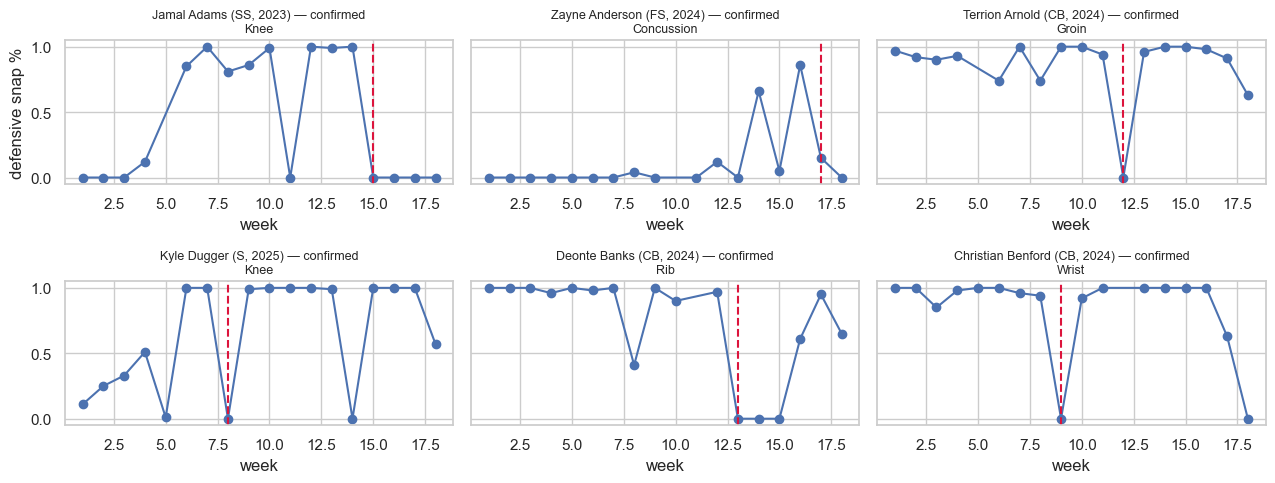

In [5]:
# Look at a few series to sanity-check the definition
show = onsets.sort_values("status").head(6)
fig, axes = plt.subplots(2, 3, figsize=(13, 5), sharey=True)
for ax, r in zip(axes.flat, show.itertuples()):
    g = grid[(grid.pfr_player_id == r.pfr_player_id) & (grid.season == r.season)]
    ax.plot(g.week, g.defense_pct, marker="o")
    ax.axvline(r.onset_week, color="crimson", ls="--")
    ax.set_title(f"{r.player} ({r.position}, {r.season}) — {r.status}\n{r.reported_injury or ''}", fontsize=9)
for ax in axes.flat:
    ax.set_xlabel("week")
axes[0, 0].set_ylabel("defensive snap %")
plt.tight_layout(); plt.show()

In [6]:
# Injured DBs we can actually study: confirmed, non-concussion, onset inside the tracking window
tracked = games.groupby("season").week.agg(["min", "max"])
injured = onsets[(onsets.status == "confirmed")
                 & (onsets.injury_group != "concussion")
                 & onsets.nflId.isin(db_ids)].copy()
injured = injured[injured.apply(lambda r: r.season in tracked.index and
                                tracked.loc[r.season, "min"] < r.onset_week <= tracked.loc[r.season, "max"] + 1,
                                axis=1)]
injured["nflId"] = injured.nflId.astype(int)
print(f"{len(injured)} confirmed DB injuries with onset inside the tracking window")
print(injured.injury_group.value_counts().to_string())
injured[["season", "player", "position", "onset_week", "reported_injury", "injury_group", "games_low"]]

29 confirmed DB injuries with onset inside the tracking window
injury_group
joint          18
other           6
soft_tissue     5


,season,player,position,onset_week,reported_injury,injury_group,games_low
10,2023,Deonte Banks,CB,17,Shoulder,joint,2
19,2023,Brian Branch,SS,5,Ankle,joint,2
20,2023,Julius Brents,CB,7,Quadricep,soft_tissue,7
131,2023,Tyrique Stevenson,CB,12,Ankle,joint,1
163,2024,Terrion Arnold,CB,12,Groin,soft_tissue,1
165,2024,Deonte Banks,CB,13,Rib,other,3
170,2024,Brian Branch,SS,4,Illness,other,1
176,2024,Javon Bullard,SS,14,Ankle,joint,3
237,2024,Kamari Lassiter,CB,6,Shoulder,joint,2
243,2024,Quan Martin,FS,18,Illness,other,1


## 2. Tracking tendencies before injury

Per DB, per game, from frames after the snap:
- **Top speed** — 90th percentile of per-play max speed (robust to one long sprint)
- **Acceleration / deceleration** — from the change in speed (signed), not the unsigned `a` column
- **Turn rate** — angle-change rate in deg/s from `dir`, only while moving > 2 yd/s
- **Speed retention through cuts** — speed 0.5 s after a hard break ÷ speed 0.5 s before

Everything is normalized to the player's own baseline, then injured DBs are compared with **matched healthy DBs** (same position group, similar snap share, same calendar weeks). Without that comparison, normal fatigue and opponent mix would look like a pre-injury signal.

In [ ]:
GAME_KEYS = ["gameId", "playId", "nflId"]

def add_frame_features(trk, keys=GAME_KEYS, fps=None):
    """Signed accel, turn rate, hard cuts, and speed retention through cuts.
    Works for game reps (gameId/playId/nflId) and Combine attempts (other keys)."""
    fps = fps or FPS
    w = max(1, int(round(RETENTION_SEC * fps)))
    trk = trk.sort_values(keys + ["frameId"]).copy()
    grp = trk.groupby(keys, sort=False)
    trk["long_acc"] = grp.s.diff() * fps                    # signed, yd/s^2
    trk["long_acc"] = grp.long_acc.transform(lambda x: x.rolling(3, center=True, min_periods=1).mean())
    unwrapped = grp.dir.transform(lambda d: np.rad2deg(np.unwrap(np.deg2rad(d.to_numpy()))))
    trk["turn_rate"] = unwrapped.groupby([trk[k] for k in keys]).diff() * fps
    trk.loc[trk.s < MIN_SPEED_FOR_DIR, "turn_rate"] = np.nan
    trk["abs_turn"] = grp.turn_rate.transform(
        lambda x: x.abs().rolling(3, center=True, min_periods=1).median())
    # hard cuts = local peaks in turn rate above threshold
    local_max = grp.abs_turn.transform(lambda x: x.rolling(5, center=True, min_periods=1).max())
    trk["is_cut"] = (trk.abs_turn >= HARD_CUT_DEG_S) & (trk.abs_turn == local_max)
    s_before, s_after = grp.s.shift(w), grp.s.shift(-w)
    trk["retention"] = np.where(trk.is_cut & (s_before > MIN_SPEED_FOR_DIR), s_after / s_before, np.nan)
    return trk


def rep_level(trk, keys=GAME_KEYS):
    return (trk.groupby(keys)
               .agg(max_s=("s", "max"), max_acc=("long_acc", "max"), max_decel=("long_acc", "min"),
                    max_turn=("abs_turn", "max"), retention=("retention", "mean"),
                    n_cuts=("is_cut", "sum"))
               .assign(max_decel=lambda d: -d.max_decel)
               .reset_index())


def game_level(pl, by=("nflId", "gameId")):
    q90 = lambda x: x.quantile(0.9)
    return (pl.groupby(list(by))
              .agg(top_speed=("max_s", q90), accel=("max_acc", q90), decel=("max_decel", q90),
                   turn_rate=("max_turn", q90), retention=("retention", "median"),
                   cuts_per_play=("n_cuts", "mean"), n_plays=("playId", "nunique"))
              .reset_index())


FEATURES = ["top_speed", "accel", "decel", "turn_rate", "retention"]

trk_db = add_frame_features(tracking[tracking.nflId.isin(db_ids)])
pl = rep_level(trk_db).merge(plays[["gameId", "playId", "quarter"]], on=["gameId", "playId"], how="left")
gl = game_level(pl).merge(games[["gameId", "season", "week"]], on="gameId")
gl = gl[gl.n_plays >= 5] 
# gl = gl[gl.n_plays >= 10]         # exclude cameos
gl[FEATURES + ["cuts_per_play", "n_plays"]].describe().T

,count,mean,std,min,25%,50%,75%,max
top_speed,1544.0,7.606095,0.547909,4.800000,7.276000,7.600000,7.951250,9.845000
accel,1544.0,5.778507,0.513921,4.100000,5.440000,5.740000,6.083333,7.826667
decel,1544.0,6.066654,0.665689,3.166667,5.666667,6.068333,6.493333,8.516667
turn_rate,1544.0,138.042370,19.017404,56.150000,126.545000,138.115000,150.040000,214.000000
retention,1348.0,1.212536,0.234104,0.067961,1.070881,1.205016,1.340743,2.090909
cuts_per_play,1544.0,0.115357,0.091435,0.000000,0.054054,0.100000,0.155268,0.714286
n_plays,1544.0,42.766192,21.383402,5.000000,24.750000,46.000000,60.000000,90.000000


### 2a. Matched controls

In [8]:
def pos_group(p):
    return "CB" if p == "CB" else "S"

base_usage = (grid.merge(id_map[["pfr_id", "nflId"]], left_on="pfr_player_id", right_on="pfr_id")
                  .groupby(["season", "nflId"]).defense_pct.median())
pos_of = players.set_index("nflId").position
ever_onset = set(zip(onsets.season, onsets.nflId.dropna()))  # any drop at all, confirmed or not
gl_weeks = gl.groupby(["season", "nflId"]).week.apply(np.array).to_dict()

controls = []
rng = np.random.default_rng(0)
for r in injured.itertuples():
    pool = [p for p in db_ids
            if (r.season, p) not in ever_onset
            and pos_group(pos_of.get(p)) == pos_group(r.position)
            and abs(base_usage.get((r.season, p), -1) - r.baseline_pct) <= 0.15
            and (gl_weeks.get((r.season, p), np.array([])) < r.onset_week).sum()
                 >= MIN_BASE_GAMES_TRK + PRE_WINDOW]
    for c in rng.choice(pool, min(N_CONTROLS, len(pool)), replace=False):
        controls.append(dict(nflId=int(c), season=r.season, onset_week=r.onset_week, match_of=r.nflId))
controls = pd.DataFrame(controls)

subjects = pd.concat([injured[["nflId", "season", "onset_week"]].assign(group="injured", match_of=injured.nflId),
                      controls.assign(group="control")], ignore_index=True)
print(subjects.group.value_counts().to_string())

group
control    62
injured    29


In [9]:
def relative_series(gl, subjects, features):
    """Each subject's games before (pseudo-)onset in that season, indexed -1, -2, ... and
    normalized to his own baseline (pre-onset games excluding the last PRE_WINDOW)."""
    out = []
    for sid, s in enumerate(subjects.itertuples()):
        g = gl[(gl.nflId == s.nflId) & (gl.season == s.season)].sort_values("week").copy()
        pre = g[g.week < s.onset_week].copy()
        if len(pre) < MIN_BASE_GAMES_TRK + PRE_WINDOW:
            continue
        pre["rel_game"] = -np.arange(len(pre), 0, -1)
        base = pre.iloc[:-PRE_WINDOW][features].median()
        onset_game = g[g.week == s.onset_week].assign(rel_game=0)    # partial game, if tracked
        both = pd.concat([pre, onset_game])
        both[features] = both[features] / base
        both["subject"], both["group"], both["match_of"] = sid, s.group, s.match_of
        out.append(both)
    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(columns=["rel_game", "subject", "group"] + features)


def cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    return (np.sign(a[:, None] - b[None, :])).mean() if len(a) and len(b) else np.nan


def mwu(a, b):
    return stats.mannwhitneyu(a, b).pvalue if len(a) > 1 and len(b) > 1 else np.nan


def compare_pre_window(rel, features):
    """Mean of last PRE_WINDOW games (normalized; 1.0 = baseline), injured vs control."""
    pre = (rel[rel.rel_game.between(-PRE_WINDOW, -1)]
             .groupby(["subject", "group"])[features].mean().reset_index())
    rows = []
    for f in features:
        a = pre.loc[pre.group == "injured", f].dropna()
        b = pre.loc[pre.group == "control", f].dropna()
        rows.append(dict(feature=f, injured_mean=a.mean(), control_mean=b.mean(),
                         n_injured=len(a), n_control=len(b), cliffs_delta=cliffs_delta(a, b), p_value=mwu(a, b)))
    return pd.DataFrame(rows), pre


rel = relative_series(gl, subjects, FEATURES)
pre_cmp, pre_by_subject = compare_pre_window(rel, FEATURES)
pre_cmp.round(3)

,feature,injured_mean,control_mean,n_injured,n_control,cliffs_delta,p_value
0,top_speed,0.984,1.001,28,62,-0.192,0.147
1,accel,0.991,0.992,28,62,-0.031,0.817
2,decel,0.963,0.983,28,62,-0.172,0.196
3,turn_rate,1.001,0.998,28,62,0.040,0.764
4,retention,1.004,1.031,28,62,-0.143,0.282


In [10]:
raw_chk = pd.read_csv("../data/game_tracking_2025.csv", usecols=["game_id", "play_id", "nfl_id"], nrows=3_000_000)
per_play = raw_chk.groupby(["game_id", "play_id"]).nfl_id.nunique()
print("players per play (unfiltered):", per_play.describe()[["mean", "50%", "max"]].to_dict())
pos = raw_chk.drop_duplicates("nfl_id").merge(raw["players"], on="nfl_id", how="left").nfl_position
print(pos.value_counts(dropna=False).head(12).to_string())

players per play (unfiltered): {'mean': 1.5251606777680398, '50%': 1.0, 'max': 6.0}
nfl_position
WR     93
CB     54
T      45
G      44
DT     43
TE     36
DE     33
OLB    28
SS     24
FS     19
C      17
NT      4


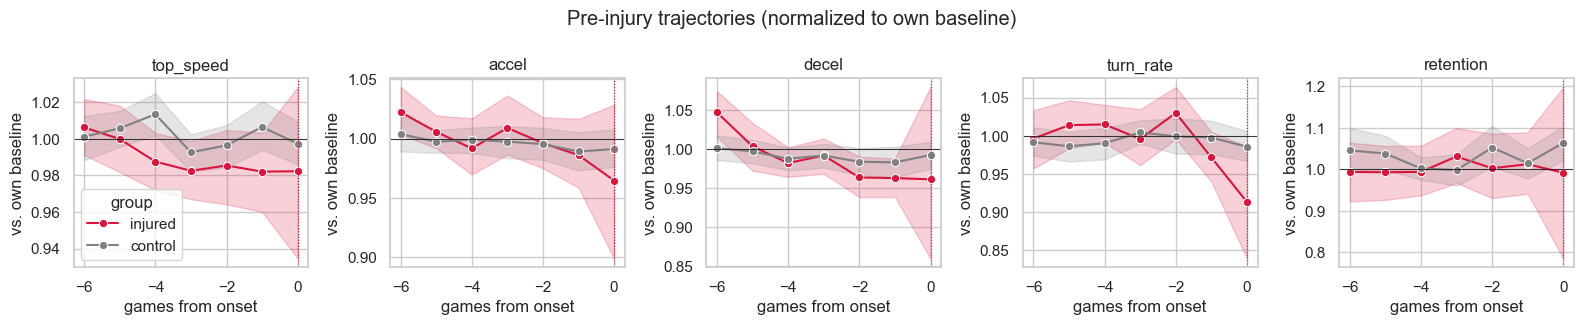

In [11]:
def plot_trajectories(rel, features, title):
    fig, axes = plt.subplots(1, len(features), figsize=(3.2 * len(features), 3.3), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, f in zip(axes, features):
        sub = rel[rel.rel_game >= -6]
        sns.lineplot(data=sub, x="rel_game", y=f, hue="group", errorbar=("ci", 90), marker="o", ax=ax,
                     palette={"injured": "crimson", "control": "grey"})
        ax.axhline(1, color="k", lw=0.6); ax.axvline(0, color="crimson", ls=":", lw=0.8)
        ax.set_title(f); ax.set_xlabel("games from onset"); ax.set_ylabel("vs. own baseline")
        if ax is not axes[0] and ax.get_legend():
            ax.get_legend().remove()
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_trajectories(rel, FEATURES, "Pre-injury trajectories (normalized to own baseline)")

## All re above cell:

rel_game
-16     2
-15     3
-14     5
-13     6
-12     8
-11    12
-10    15
-9     16
-8     19
-7     20
-6     21
-5     25
-4     28
-3     28
-2     28
-1     28
 0      7


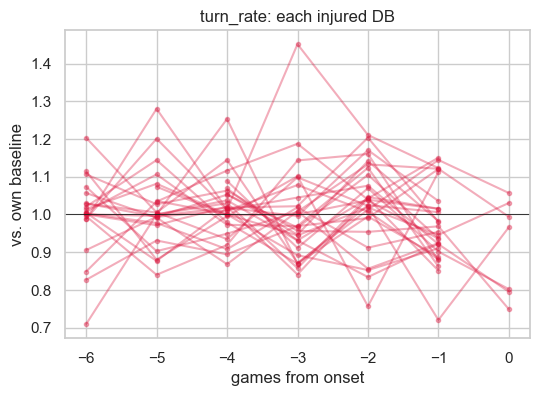

n injured=28, control=62 | Cliff's delta=0.24 | p=0.068
drop > 0.03: injured 57% vs control 39%
drop > 0.05: injured 54% vs control 32%
drop > 0.10: injured 46% vs control 27%
2023 n_inj=4 delta=1.00
2024 n_inj=10 delta=0.22
2025 n_inj=14 delta=0.16
median: injured 1.316 vs control 0.991 | Cliff's delta=0.23 | p=0.081
cuts > 1.10x baseline: injured 64% vs control 42%
cuts > 1.20x baseline: injured 61% vs control 34%
2023 n_inj=4 delta=0.25
2024 n_inj=10 delta=0.38
2025 n_inj=14 delta=0.10
         mean  sum  size
group                   
control  0.21   13    62
injured  0.43   12    28
drop_thr  0.03  0.05  0.08  0.10
cuts_thr                        
1.05      2.06  1.90  1.87  1.85
1.10      2.21  2.04  2.03  2.01
1.15      2.21  2.04  2.03  2.01
1.20      2.42  2.21  2.21  2.21
1.30      2.44  2.21  2.21  2.21

soft tissue: {'mean': {'control': 0.32, 'injured': 0.5}, 'sum': {'control': 7, 'injured': 5}, 'size': {'control': 22, 'injured': 10}}
joint: {'mean': {'control': 0.23, 'injur

C:\Users\bchm5\AppData\Local\Temp\ipykernel_30612\3676060502.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sd = rel.groupby(["subject", "group"]).apply(spike_drop).rename("spike_drop").reset_index()


In [32]:
# 1. Is it a few players or most of them?
f = "turn_rate"
inj = rel[rel.group == "injured"]
print(inj.groupby("rel_game").subject.nunique().rename("n injured players").to_string())

fig, ax = plt.subplots(figsize=(6, 4))
for sid, g in inj[inj.rel_game >= -6].groupby("subject"):
    ax.plot(g.rel_game, g[f], color="crimson", alpha=0.35, marker=".")
ax.axhline(1, color="k", lw=0.6)
ax.set_title(f"{f}: each injured DB"); ax.set_xlabel("games from onset"); ax.set_ylabel("vs. own baseline")
plt.show()

# 2. Was the spike game a heavier workload?
base = rel[rel.rel_game < -PRE_WINDOW].groupby("subject")[["cuts_per_play", "n_plays"]].median()
r2 = rel.join(base, on="subject", rsuffix="_base")
r2["cuts_norm"] = r2.cuts_per_play / r2.cuts_per_play_base
r2["plays_norm"] = r2.n_plays / r2.n_plays_base
(r2[r2.rel_game.between(-3, 0)]
   .groupby(["group", "rel_game"])[["turn_rate", "cuts_norm", "plays_norm"]].mean().round(3))

# 3. Test the shape directly
def spike_drop(g, f="turn_rate"):
    s = g.set_index("rel_game")[f]
    return s[-2] - s[-1] if {-2, -1} <= set(s.index) else np.nan

sd = rel.groupby(["subject", "group"]).apply(spike_drop).rename("spike_drop").reset_index()
a = sd.loc[sd.group == "injured", "spike_drop"].dropna()
b = sd.loc[sd.group == "control", "spike_drop"].dropna()
print(f"n injured={len(a)}, control={len(b)} | Cliff's delta={cliffs_delta(a, b):.2f} | p={mwu(a, b):.3f}")
for t in [0.03, 0.05, 0.10]:
    print(f"drop > {t:.2f}: injured {(a > t).mean():.0%} vs control {(b > t).mean():.0%}")

# 4. Check across seasons
sd = sd.merge(subjects.reset_index().rename(columns={"index": "subject"})[["subject", "season"]], on="subject")
for yr, g in sd.groupby("season"):
    a = g.loc[g.group == "injured", "spike_drop"].dropna(); b = g.loc[g.group == "control", "spike_drop"].dropna()
    print(yr, f"n_inj={len(a)}", f"delta={cliffs_delta(a, b):.2f}")

# 5. Test the cutting spike directly
r2["subject_season"] = r2.subject.map(subjects.season)
cs = r2[r2.rel_game == -2][["subject", "group", "subject_season", "cuts_norm"]].dropna()
a = cs.loc[cs.group == "injured", "cuts_norm"]; b = cs.loc[cs.group == "control", "cuts_norm"]
print(f"median: injured {a.median():.3f} vs control {b.median():.3f} | "
      f"Cliff's delta={cliffs_delta(a, b):.2f} | p={mwu(a, b):.3f}")
for t in [1.10, 1.20]:
    print(f"cuts > {t:.2f}x baseline: injured {(a > t).mean():.0%} vs control {(b > t).mean():.0%}")
for yr, g in cs.groupby("subject_season"):
    print(yr, f"n_inj={(g.group == 'injured').sum()}",
          f"delta={cliffs_delta(g.loc[g.group == 'injured', 'cuts_norm'], g.loc[g.group == 'control', 'cuts_norm']):.2f}")

# 6. Do the two patterns go together?
sig = sd.merge(cs[["subject", "cuts_norm"]], on="subject")
sig["signature"] = (sig.cuts_norm > 1.10) & (sig.spike_drop > 0.05)
print(sig.groupby("group").signature.agg(["mean", "sum", "size"]).round(2))

# 7. Is it stable across thresholds, or did 1.10 / 0.05 just happen to work?
grid = []
for ct in [1.05, 1.10, 1.15, 1.20, 1.30]:
    for dt in [0.03, 0.05, 0.08, 0.10]:
        s = (sig.cuts_norm > ct) & (sig.spike_drop > dt)
        grid.append(dict(cuts_thr=ct, drop_thr=dt,
                         ratio=s[sig.group == "injured"].mean() / max(s[sig.group == "control"].mean(), 1e-9)))
print(pd.DataFrame(grid).pivot(index="cuts_thr", columns="drop_thr", values="ratio").round(2))

# 8. Soft-tissue injuries only (where a cutting-load link makes the most sense)
soft = set(injured.loc[injured.injury_group == "soft_tissue", "nflId"])
sig["match_of"] = sig.subject.map(subjects.match_of)
sub = sig[sig.match_of.isin(soft)]
print("\nsoft tissue:", sub.groupby("group").signature.agg(["mean", "sum", "size"]).round(2).to_dict())

# 9. Joint injuries only (where a cutting-load link may be less relevant)
joint = set(injured.loc[injured.injury_group == "joint", "nflId"])
sub_j = sig[sig.match_of.isin(joint)]
print("joint:", sub_j.groupby("group").signature.agg(["mean", "sum", "size"]).round(2).to_dict())

# 10. Injury group breakdown
sig["season"] = sig.subject.map(subjects.season)
group_of = {(r.season, r.nflId): r.injury_group for r in injured.itertuples()}
sig["injury_group"] = [group_of.get((s, m)) for s, m in zip(sig.season, sig.match_of)]

print(sig.groupby(["injury_group", "group"]).signature.agg(["mean", "sum", "size"]).round(2))
print("\ninjured total:", (sig.group == "injured").sum(), "| control total:", (sig.group == "control").sum())

LOWER = ["knee", "ankle", "foot", "hip", "toe", "acl", "mcl", "achilles"]
inj_txt = {(r.season, r.nflId): str(r.reported_injury).lower() for r in injured.itertuples()}
sig["lower_body"] = [any(k in inj_txt.get((s, m), "") for k in LOWER) for s, m in zip(sig.season, sig.match_of)]
print(sig.groupby(["lower_body", "group"]).signature.agg(["mean", "sum", "size"]).round(2))

LEG = ["knee", "ankle", "foot", "hip", "toe", "acl", "mcl", "achilles",
       "hamstring", "groin", "calf", "quad", "thigh", "shin", "leg"]
UPPER = ["shoulder", "wrist", "elbow", "hand", "finger", "pectoral", "chest", "rib", "arm", "back", "neck"]

def region(txt):
    t = str(txt).lower()
    return "leg" if any(k in t for k in LEG) else "upper" if any(k in t for k in UPPER) else "other"

region_of = {(r.season, r.nflId): region(r.reported_injury) for r in injured.itertuples()}
sig["region"] = [region_of.get((s, m)) for s, m in zip(sig.season, sig.match_of)]
print(sig.groupby(["region", "group"]).signature.agg(["mean", "sum", "size"]).round(2))

pre_rep = injuries.merge(injured[["season", "gsis_id", "onset_week", "nflId"]], on=["season", "gsis_id"])
pre_rep = pre_rep[pre_rep.week.between(pre_rep.onset_week - 2, pre_rep.onset_week - 1)]
flagged = set(zip(pre_rep.season, pre_rep.nflId))

inj_sig = sig[sig.group == "injured"].copy()
inj_sig["on_report_before_onset"] = [(s, m) in flagged for s, m in zip(inj_sig.season, inj_sig.match_of)]
print(pd.crosstab(inj_sig.signature, inj_sig.on_report_before_onset, margins=True))

### 2b. Within-game taper

Does a DB's speed / turning fall off from Q1 to Q4, and is the fade steeper in the games right before an injury? Each game is normalized to its own Q1 so the comparison is the *shape* of the game, not the level.

In [12]:
def taper_slopes(pl, features):
    gq = game_level(pl, by=("nflId", "gameId", "quarter")).merge(games[["gameId", "season", "week"]], on="gameId")
    gq = gq[gq.quarter.between(1, 4) & (gq.n_plays >= 3)]              # drop OT
    rows = []
    for (pid, gid), g in gq.groupby(["nflId", "gameId"]):
        g = g.sort_values("quarter")
        if g.quarter.nunique() < 3 or 1 not in set(g.quarter):
            continue
        q1 = g[g.quarter == 1][features].iloc[0]
        row = dict(nflId=pid, gameId=gid, season=g.season.iloc[0], week=g.week.iloc[0])
        for f in features:
            y = (g[f] / q1[f]).to_numpy()
            ok = np.isfinite(y)
            row[f"{f}_taper"] = np.polyfit(g.quarter.to_numpy()[ok], y[ok], 1)[0] if ok.sum() >= 3 else np.nan
        rows.append(row)
    return gq, pd.DataFrame(rows)


gq, taper = taper_slopes(pl, FEATURES)
TAPER = [f"{f}_taper" for f in FEATURES]

def subject_weeks(s, table, n=PRE_WINDOW):
    w = table[(table.nflId == s.nflId) & (table.season == s.season) & (table.week < s.onset_week)]
    return w.sort_values("week").tail(n)

taper_rows = []
for sid, s in enumerate(subjects.itertuples()):
    t = subject_weeks(s, taper)
    if len(t):
        taper_rows.append(t[TAPER].mean().to_dict() | dict(subject=sid, group=s.group))
taper_pre = pd.DataFrame(taper_rows)
taper_cmp = []
for f in TAPER:
    a = taper_pre.loc[taper_pre.group == "injured", f].dropna()
    b = taper_pre.loc[taper_pre.group == "control", f].dropna()
    taper_cmp.append(dict(feature=f, injured_mean=a.mean(), control_mean=b.mean(),
                          cliffs_delta=cliffs_delta(a, b), p_value=mwu(a, b)))
taper_cmp = pd.DataFrame(taper_cmp)
print("Slope per quarter, relative to Q1 (negative = fading)")
taper_cmp.round(4)

Slope per quarter, relative to Q1 (negative = fading)


,feature,injured_mean,control_mean,cliffs_delta,p_value
0,top_speed_taper,-0.0095,0.0032,-0.2481,0.0581
1,accel_taper,0.0057,-0.0045,0.1802,0.1690
2,decel_taper,0.0043,-0.0057,0.1313,0.3169
3,turn_rate_taper,0.0115,0.0043,0.1379,0.2928
4,retention_taper,0.0047,-0.0100,-0.0758,0.6776


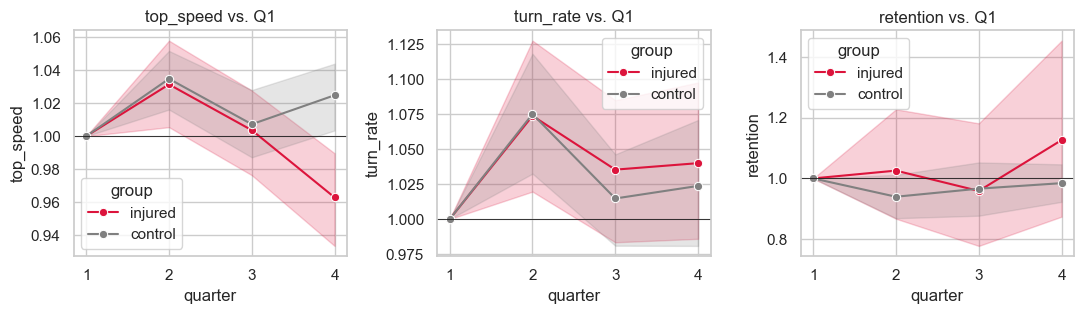

In [13]:
# Q1 -> Q4 profile, pre-injury games vs controls
q1 = gq[gq.quarter == 1].set_index(["nflId", "gameId"])[FEATURES]
gq_rel = gq.join(q1, on=["nflId", "gameId"], rsuffix="_q1")
for f in FEATURES:
    gq_rel[f] = gq_rel[f] / gq_rel[f"{f}_q1"]
lab = pd.concat([gq_rel[(gq_rel.nflId == s.nflId) & (gq_rel.season == s.season)
                        & gq_rel.week.isin(subject_weeks(s, gl).week)].assign(group=s.group)
                 for s in subjects.itertuples()], ignore_index=True)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, f in zip(axes, ["top_speed", "turn_rate", "retention"]):
    sns.lineplot(data=lab, x="quarter", y=f, hue="group", marker="o", errorbar=("ci", 90), ax=ax,
                 palette={"injured": "crimson", "control": "grey"})
    ax.axhline(1, color="k", lw=0.6); ax.set_title(f"{f} vs. Q1")
plt.tight_layout(); plt.show()

### 2c. Change point on the performance series

Same tool as Step 1, pointed at tracking instead of snaps: does a downward change point in a DB's game-by-game top speed or retention show up **before** the injury, and how often does it fire for healthy controls (false alarms)?

In [14]:
def perf_changepoint(series, min_drop=0.04):
    """Single best split on a normalized series; returns index of first 'after' game if mean drops >= min_drop."""
    y = np.asarray(series, float)
    y = y[np.isfinite(y)]
    if len(y) < 4:
        return None
    best, best_cost = None, np.inf
    for k in range(2, len(y) - 1):
        cost = ((y[:k] - y[:k].mean()) ** 2).sum() + ((y[k:] - y[k:].mean()) ** 2).sum()
        if cost < best_cost:
            best, best_cost = k, cost
    return best if y[:best].mean() - y[best:].mean() >= min_drop else None


cp_rows = []
for (sid, grp_), g in rel[rel.rel_game < 0].groupby(["subject", "group"]):
    g = g.sort_values("rel_game")
    for f in ["top_speed", "retention", "turn_rate"]:
        k = perf_changepoint(g[f].to_numpy())
        cp_rows.append(dict(subject=sid, group=grp_, feature=f, fired=k is not None,
                            lead_games=(len(g) - k) if k is not None else np.nan))
cp = pd.DataFrame(cp_rows)
cp.groupby(["feature", "group"]).agg(rate=("fired", "mean"), median_lead_games=("lead_games", "median"),
                                     n=("fired", "size")).unstack("group").round(2)

rate         median_lead_games               n        
group     control injured           control injured control injured
feature                                                            
retention    0.50    0.57               4.0     5.5      62      28
top_speed    0.42    0.50               8.0     4.0      62      28
turn_rate    0.48    0.46               6.0     3.0      62      28

## 3. Correlate to the Combine

Three questions:
1. Which Combine results line up with in-game speed, turning, and retention? If none line up with turning / retention, the Combine is missing that trait.
2. Do Combine results differ between injured and healthy DBs?
3. **(3b)** Using `combine_tracking.csv`: does the *movement* inside the agility drills (turn rate, speed kept through the cones) capture in-game turning better than the drill *times* do?

88 of 88 tracked DBs have Combine results


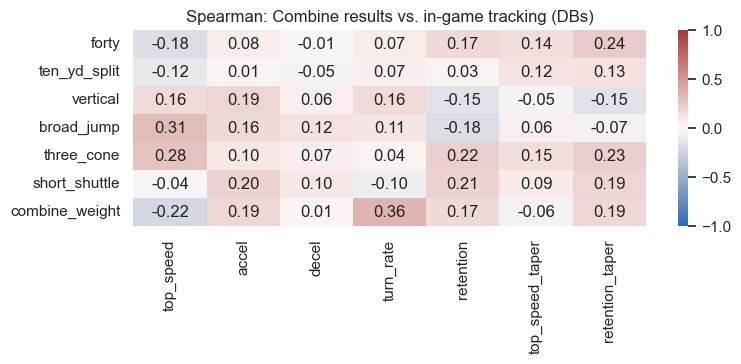

In [15]:
COMBINE_COLS = ["forty", "ten_yd_split", "vertical", "broad_jump", "three_cone", "short_shuttle", "combine_weight"]
GAME_COLS = FEATURES + ["top_speed_taper", "retention_taper"]

player_tbl = (gl.groupby("nflId")[FEATURES].median()
                .join(taper.groupby("nflId")[TAPER].mean())
                .reset_index())
player_tbl["injured"] = player_tbl.nflId.isin(injured.nflId)
player_tbl = player_tbl.merge(combine_res.drop_duplicates("nflId", keep="last")[["nflId"] + COMBINE_COLS],
                              on="nflId", how="left")
print(f"{player_tbl[COMBINE_COLS].notna().any(axis=1).sum()} of {len(player_tbl)} tracked DBs have Combine results")

def corr_heatmap(df, rows, cols, title, figsize=(8, 3.8)):
    c = df[rows + cols].corr(method="spearman").loc[rows, cols]
    plt.figure(figsize=figsize)
    sns.heatmap(c, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
    plt.title(title); plt.tight_layout(); plt.show()
    return c

corr = corr_heatmap(player_tbl, COMBINE_COLS, GAME_COLS, "Spearman: Combine results vs. in-game tracking (DBs)")

In [16]:
comb_cmp = []
for c in COMBINE_COLS:
    a = player_tbl.loc[player_tbl.injured, c].dropna()
    b = player_tbl.loc[~player_tbl.injured, c].dropna()
    comb_cmp.append(dict(drill=c, injured_median=a.median(), healthy_median=b.median(),
                         n_injured=len(a), n_healthy=len(b), cliffs_delta=cliffs_delta(a, b), p_value=mwu(a, b)))
pd.DataFrame(comb_cmp).round(3)

,drill,injured_median,healthy_median,n_injured,n_healthy,cliffs_delta,p_value
0,forty,4.49,4.47,15,61,0.096,0.570
1,ten_yd_split,1.53,1.53,15,61,-0.028,0.870
2,vertical,38.50,36.00,15,59,0.416,0.013
3,broad_jump,125.50,123.50,16,52,0.258,0.121
4,three_cone,6.88,6.99,5,13,-0.338,0.299
5,short_shuttle,4.22,4.28,6,17,-0.078,0.806
6,combine_weight,194.00,195.00,20,68,-0.146,0.324


### 3b. Movement inside the Combine drills

Same frame features as the game data (turn rate, speed retention through cuts, accel/decel), computed per drill attempt from `combine_tracking.csv`, then averaged over a player's attempts.

In [17]:
print(combine_trk.groupby(["drill_type", "drill_name"]).event_id.nunique().rename("attempts").to_string())
print("entity_type:", combine_trk.entity_type.unique())

COMBINE_KEYS = ["nflId", "event_id", "drill_name", "attempt"]
ct = combine_trk[combine_trk.nflId.isin(db_ids)].dropna(subset=["nflId"])
ct, CT_FPS = prep_tracking(ct, COMBINE_KEYS)
print(f"combine tracking at {CT_FPS:.0f} Hz")
ct = add_frame_features(ct, keys=COMBINE_KEYS, fps=CT_FPS)
attempts = (rep_level(ct, COMBINE_KEYS)
              .merge(ct.groupby(COMBINE_KEYS).time.agg(lambda t: (t.max() - t.min()).total_seconds())
                       .rename("duration").reset_index(), on=COMBINE_KEYS))
ct_player = (attempts.groupby(["nflId", "drill_name"])[["max_s", "max_turn", "retention", "max_decel", "duration"]]
                     .median().unstack("drill_name"))
ct_player.columns = [f"{d}|{f}" for f, d in ct_player.columns]
ct_player = ct_player.dropna(axis=1, thresh=10).reset_index()

# which tracked-drill measures best match in-game turning / retention?
pt = player_tbl.merge(ct_player, on="nflId", how="left")
CT_COLS = [c for c in ct_player.columns if c != "nflId"]
drill_vs_game = (pt[CT_COLS + ["turn_rate", "retention", "top_speed"]].corr(method="spearman")
                   .loc[CT_COLS, ["turn_rate", "retention", "top_speed"]])
drill_vs_game["n"] = [pt[[c, "retention"]].dropna().shape[0] for c in CT_COLS]
drill_vs_game.sort_values("retention", key=abs, ascending=False).round(2)

drill_type        drill_name                                  
FORTY_YARD_DASH   FORTY_YARD_DASH                                 189
SHORT_SHUTTLE     SHORT_SHUTTLE                                    35
SKILL_DRILLS_DB   BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL          120
                  BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION    233
                  BOX_DRILL                                       121
                  GAUNTLET_DRILL                                  119
                  LINE                                             50
                  LINE_DRILL                                      159
                  TERYL_AUSTIN_DRILL_1                             99
                  TERYL_AUSTIN_DRILL_2                            109
                  W_DRILL                                         120
THREE_CONE_DRILL  THREE_CONE_DRILL                                 29
entity_type: ['PLAYER']
combine tracking at 10 Hz


,turn_rate,retention,top_speed,n
SHORT_SHUTTLE|max_s,0.08,0.36,-0.27,21
BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL|max_s,0.18,0.32,-0.09,87
THREE_CONE_DRILL|max_turn,-0.25,-0.29,-0.11,18
LINE|duration,0.31,-0.29,-0.09,27
LINE|max_turn,0.46,0.28,-0.14,27
LINE|max_s,-0.44,0.25,-0.11,27
BOX_DRILL|max_s,0.05,0.24,0.03,87
TERYL_AUSTIN_DRILL_1|max_decel,-0.02,0.24,-0.02,71
TERYL_AUSTIN_DRILL_1|max_turn,-0.18,-0.20,0.17,71
W_DRILL|max_s,0.09,0.19,-0.10,87


## 4. Toward a 1-on-1 Combine drill

The Combine tests DBs alone. In games, a DB reacts to a receiver. The ideal game measure would be **mirror lag**: how quickly a DB turns after the receiver he's covering breaks. This dataset tracks about 1.5 players per play, though, so a DB and his receiver are rarely tracked on the same play and mirror lag can't be measured.

The proposal below rests on the single-player measures from Sections 2 and 3b. The missing reaction measure is part of the argument: game tracking shows how a DB moves but rarely what he's reacting to, and a tracked 1-on-1 drill captures both by design.

### Summary table

In [18]:
summary = pd.concat([
    pre_cmp.assign(test="pre-injury level (2a)"),
    taper_cmp.assign(test="in-game taper (2b)"),
])[["test", "feature", "injured_mean", "control_mean", "cliffs_delta", "p_value"]]
summary["abs_effect"] = summary.cliffs_delta.abs()
display(summary.sort_values("abs_effect", ascending=False).round(3))

best = pd.DataFrame({"best |rho|, Combine results": corr.abs().max(axis=0),
                     "best |rho|, tracked drills": drill_vs_game.drop(columns="n").abs().max(axis=0)})
display(best.round(2))

,test,feature,injured_mean,control_mean,cliffs_delta,p_value,abs_effect
0,in-game taper (2b),top_speed_taper,-0.010,0.003,-0.248,0.058,0.248
0,pre-injury level (2a),top_speed,0.984,1.001,-0.192,0.147,0.192
1,in-game taper (2b),accel_taper,0.006,-0.005,0.180,0.169,0.180
2,pre-injury level (2a),decel,0.963,0.983,-0.172,0.196,0.172
4,pre-injury level (2a),retention,1.004,1.031,-0.143,0.282,0.143
3,in-game taper (2b),turn_rate_taper,0.011,0.004,0.138,0.293,0.138
2,in-game taper (2b),decel_taper,0.004,-0.006,0.131,0.317,0.131
4,in-game taper (2b),retention_taper,0.005,-0.010,-0.076,0.678,0.076
3,pre-injury level (2a),turn_rate,1.001,0.998,0.040,0.764,0.040
1,pre-injury level (2a),accel,0.991,0.992,-0.031,0.817,0.031


,"best |rho|, Combine results","best |rho|, tracked drills"
accel,0.20,NaN
decel,0.12,NaN
retention,0.22,0.36
retention_taper,0.24,NaN
top_speed,0.31,0.36
top_speed_taper,0.15,NaN
turn_rate,0.36,0.46


### Drill proposal (draft — fill in with results)

**Tracked Mirror-and-Break drill.** A DB mirrors a receiver (or a programmable light or robot cue) running randomized breaks, with both tracked by the same chips used in games.

| Measure | Evidence from this notebook | Section |
|---|---|---|
| Reaction lag to the break | Not measurable in BDB tracking (about 1.5 tracked players per play); the drill would capture it | — |
| Speed kept through the turn | `retention` | 2a, 3b |
| Peak turn rate | `turn_rate` | 2a, 3b |
| Decline across 6–8 reps | in-game taper | 2b |

**Argument:** *[fill in]* The measures that separated injured DBs from matched healthy DBs were ___. The best any current Combine result correlated with them was ρ = ___ (ρ = ___ using movement tracked inside the existing drills, Section 3b). The proposed drill measures these traits directly and adds the one game tracking can't capture: reaction to a live opponent.

**Caveats to state up front:** small number of injured DBs; injury defined from snaps and injury reports, not medical records; BDB tracks a subset of players per play; results are a proof of concept for what a tracked drill could capture.

In [35]:
# ---------------- 2d. Player profiles: injured vs. healthy DB seasons ----------------
SPIKE_THR = 1.20      # cutting spike = cuts per play > 1.2x recent baseline
MIN_GAMES = 4         # tracked games needed in a player's window
EXCLUDE_LAST = 2      # drop the last N games before (pseudo-)onset; 0 = keep all

# game-by-game measures for every DB, against a rolling baseline (prior 3 games)
tr = gl.sort_values(["nflId", "season", "week"]).copy()
by = tr.groupby(["nflId", "season"])
for f in ["cuts_per_play", "turn_rate"]:
    tr[f + "_base"] = by[f].transform(lambda x: x.shift(1).rolling(3, min_periods=2).median())
tr["cuts_norm"] = tr.cuts_per_play / tr.cuts_per_play_base
tr["spike"] = tr.cuts_norm > SPIKE_THR
tr["turn_next"] = by.turn_rate.shift(-1) / tr.turn_rate_base
tr["next_week"] = by.week.shift(-1)
tr = tr.merge(taper[["nflId", "gameId"] + TAPER], on=["nflId", "gameId"], how="left")

# windows: injured = games before onset; healthy regulars = games before a pseudo-onset
# drawn from the injured onset weeks, so both groups are measured over similar stretches
inj_onset = {(r.season, r.nflId): r.onset_week for r in injured.itertuples()}
any_drop = {(r.season, int(r.nflId)) for r in onsets.dropna(subset=["nflId"]).itertuples()}
rng_p = np.random.default_rng(1)
windows = [(s, n, w, "injured") for (s, n), w in inj_onset.items()]
for (s, n), usage in base_usage.items():
    if usage >= BASELINE_MIN_PCT and (s, n) not in any_drop and n in db_ids:
        windows.append((s, int(n), int(rng_p.choice(injured.onset_week)), "healthy"))

rows = []
for s, n, end, grp in windows:
    g = tr[(tr.nflId == n) & (tr.season == s) & (tr.week < end)].sort_values("week")
    if EXCLUDE_LAST:
        g = g.iloc[:-EXCLUDE_LAST]
    if len(g) < MIN_GAMES:
        continue
    x = np.arange(len(g))
    r = dict(season=s, nflId=n, group=grp, games=len(g))
    for f in FEATURES + ["cuts_per_play"]:
        r[f"{f}_level"] = g[f].median()
    for f in ["top_speed", "turn_rate", "cuts_per_play"]:
        v = g[f] / g[f].median()
        r[f"{f}_variability"] = v.std()
        r[f"{f}_trend"] = np.polyfit(x[v.notna()], v.dropna(), 1)[0] if v.notna().sum() >= MIN_GAMES else np.nan
    r["spike_rate"] = g.spike.mean()
    rec = g.loc[g.spike & (g.next_week < end), "turn_next"]
    r["turn_after_spike"], r["n_spikes"] = rec.median(), len(rec)
    for t in ["top_speed_taper", "turn_rate_taper"]:
        r[t] = g[t].mean()
    rows.append(r)
prof = pd.DataFrame(rows)
prof["pos_group"] = prof.nflId.map(pos_of).map(pos_group)

# levels differ by position and season -> z-score them within season x position group
LEVELS = [c for c in prof.columns if c.endswith("_level")]
prof[LEVELS] = prof.groupby(["season", "pos_group"])[LEVELS].transform(lambda x: (x - x.mean()) / x.std())

# Combine results, z-scored within position group
prof = prof.merge(combine_res.drop_duplicates("nflId", keep="last")[["nflId"] + COMBINE_COLS], on="nflId", how="left")
prof[COMBINE_COLS] = prof.groupby("pos_group")[COMBINE_COLS].transform(lambda x: (x - x.mean()) / x.std())

print(prof.groupby("group").agg(player_seasons=("nflId", "size"), median_games=("games", "median")).to_string())

METRICS = [c for c in prof.columns if c not in ("season", "nflId", "group", "games", "pos_group", "n_spikes")]
prof_cmp = []
for m in METRICS:
    a = prof.loc[prof.group == "injured", m].dropna()
    b = prof.loc[prof.group == "healthy", m].dropna()
    by_season = [cliffs_delta(prof.loc[(prof.group == "injured") & (prof.season == s), m].dropna(),
                              prof.loc[(prof.group == "healthy") & (prof.season == s), m].dropna())
                 for s in SEASONS]
    prof_cmp.append(dict(metric=m, injured_median=a.median(), healthy_median=b.median(),
                         n_injured=len(a), n_healthy=len(b), cliffs_delta=cliffs_delta(a, b), p_value=mwu(a, b),
                         same_sign_all_seasons=(lambda v: len(v) >= 2 and all(np.sign(x) == np.sign(cliffs_delta(a, b)) for x in v))(
                             [d for d in by_season if np.isfinite(d)]),
                         season_deltas=[round(d, 2) if np.isfinite(d) else None for d in by_season]))
prof_cmp = pd.DataFrame(prof_cmp).sort_values("cliffs_delta", key=abs, ascending=False).reset_index(drop=True)
display(prof_cmp.round(3))

         player_seasons  median_games
group                                
healthy              17          10.0
injured              21           9.0


,metric,injured_median,healthy_median,n_injured,n_healthy,cliffs_delta,p_value,same_sign_all_seasons,season_deltas
0,short_shuttle,0.680,-1.120,6,3,0.556,0.241,True,"[None, 1.0, 0.5]"
1,top_speed_trend,-0.004,0.002,21,17,-0.513,0.008,True,"[None, -0.54, -0.44]"
2,retention_level,0.484,-0.471,21,17,0.361,0.060,True,"[None, 0.49, 0.33]"
3,turn_rate_variability,0.098,0.079,21,17,0.333,0.083,False,"[None, -0.31, 0.51]"
4,three_cone,0.648,0.264,5,3,0.267,0.649,False,"[None, 1.0, -0.33]"
5,cuts_per_play_variability,0.638,0.536,21,17,0.249,0.196,False,"[None, -0.14, 0.4]"
6,cuts_per_play_trend,0.003,-0.017,21,17,0.176,0.363,True,"[None, 0.31, 0.18]"
7,turn_rate_trend,0.003,0.000,21,17,0.165,0.395,True,"[None, 0.2, 0.29]"
8,top_speed_level,0.116,-0.461,21,17,0.154,0.428,False,"[None, 0.49, -0.04]"
9,top_speed_taper,-0.006,-0.006,21,17,0.126,0.518,False,"[None, 0.37, 0.0]"


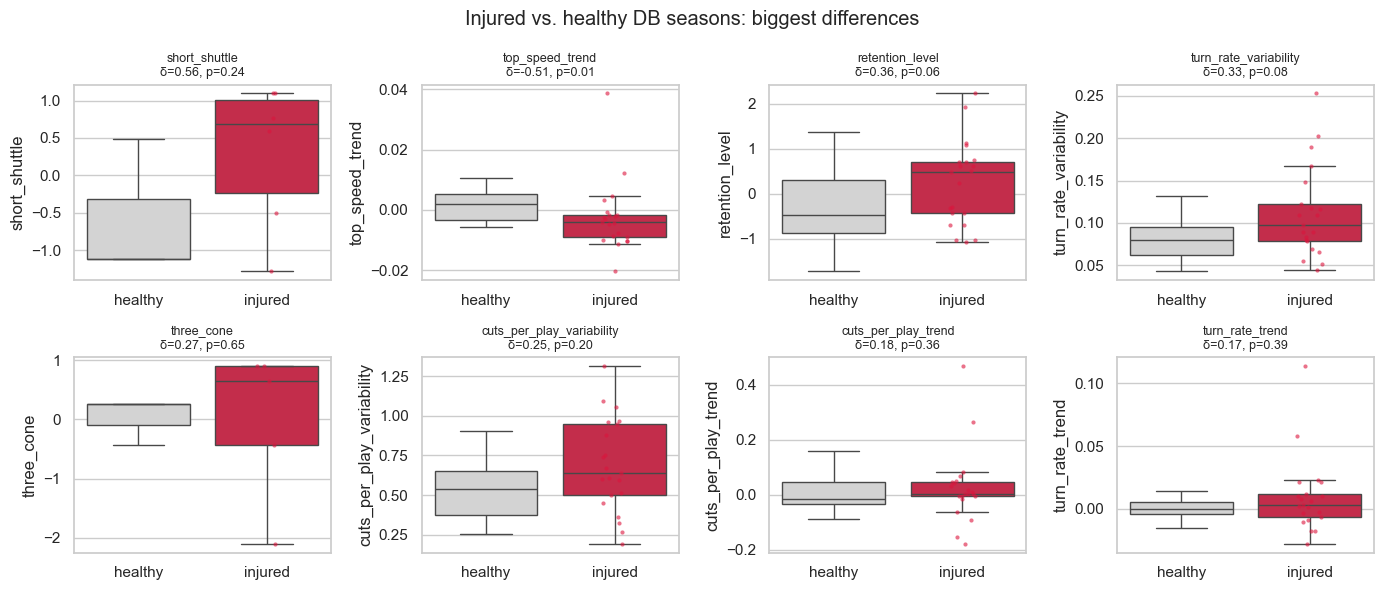

In [36]:
top = prof_cmp.metric.head(8).tolist()
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, m in zip(axes.flat, top):
    sns.boxplot(data=prof, x="group", y=m, hue="group", legend=False, order=["healthy", "injured"], ax=ax,
                palette={"injured": "crimson", "healthy": "lightgrey"}, showfliers=False)
    sns.stripplot(data=prof[prof.group == "injured"], x="group", y=m, order=["healthy", "injured"],
                  ax=ax, color="crimson", size=3, alpha=0.6)
    d = prof_cmp.set_index("metric").loc[m]
    ax.set_title(f"{m}\nδ={d.cliffs_delta:.2f}, p={d.p_value:.2f}", fontsize=9); ax.set_xlabel("")
plt.suptitle("Injured vs. healthy DB seasons: biggest differences"); plt.tight_layout(); plt.show()